# PNM Generation and Mercury Intrusion Simulation




This notebook demonstrates how to generate a random pore network model (PNM)
from experimental mercury intrusion porosimetry (MIP) data, compare the generated
network against the experimental distributions, run a mercury intrusion simulation,
and visualize the resulting 3D network.

**Key concept:** The experimental MIP data provides the **throat (capillary)**
size distribution. From this distribution, we predict the corresponding **pore**
size distribution such that, when pores are connected by throats, the measured
throat distribution is recovered.

**Workflow:**
1. Read all experimental source files (CSV) and plot their intrusion curves
2. Select one file and prepare the experimental throat distribution
3. Predict the pore distribution from the throat distribution (corrective factor `e`, PRTRR)
4. Define model parameters (number of pores, surface coverage ratio, etc.)
5. Generate a pore network using the predicted pore distribution
6. Compare experimental vs generated throat/pore distributions
7. Mercury intrusion simulation: compare experimental vs simulated curves
8. 3D visualization and image saving

Generated networks are saved in `examples/networks/`.



## 1. Imports and Configuration



In [1]:
# Add project root to Python path so the 'pnm' package can be imported
import sys
from pathlib import Path
sys.path.insert(0, "/home/jlux/Nextcloud/Codes/python3/pnm")

import os
import csv
import numpy as np
import matplotlib.pyplot as plt
from functools import partial
from datetime import datetime

# Plotting inline
%matplotlib inline

# PNM package
import pnm
from pnm import pore_network
from pnm.Generators import random_PNM
from pnm.Algorithms.percolation import mercury_intrusion
from pnm.Stats import stats, distribution, inverse_transform_sampling_from_raw_data

# Project paths
PROJECT_ROOT = Path("/home/jlux/Nextcloud/Codes/python3/pnm")
DATA_DIR = PROJECT_ROOT / "examples" / "data"
NETWORKS_DIR = PROJECT_ROOT / "examples" / "networks"
NETWORKS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Data directory: {DATA_DIR}")
print(f"Networks directory: {NETWORKS_DIR}")


Project root: /home/jlux/Nextcloud/Codes/python3/pnm
Data directory: /home/jlux/Nextcloud/Codes/python3/pnm/examples/data
Networks directory: /home/jlux/Nextcloud/Codes/python3/pnm/examples/networks


## 2. Read All Source Files




The `examples/data/` directory contains CSV files with mercury intrusion porosimetry
data. Each file has two columns: pore **diameter** and cumulative intruded **volume**.

All experimental intrusion curves are plotted below so you can choose which file
to use for network generation. Modify `selected_file_index` in the next cell.



In [2]:
csv_files = sorted([f for f in os.listdir(DATA_DIR) if f.endswith(".csv")])
print(f"Found {len(csv_files)} CSV file(s) in {DATA_DIR}:")
for i, f in enumerate(csv_files):
    print(f"  [{i}] {f}")


Found 6 CSV file(s) in /home/jlux/Nextcloud/Codes/python3/pnm/examples/data:
  [0] GM1.csv
  [1] GM2-EMPA.csv
  [2] GM2.csv
  [3] MP.csv
  [4] PCI.csv
  [5] PCV.csv


### Plot all experimental intrusion curves



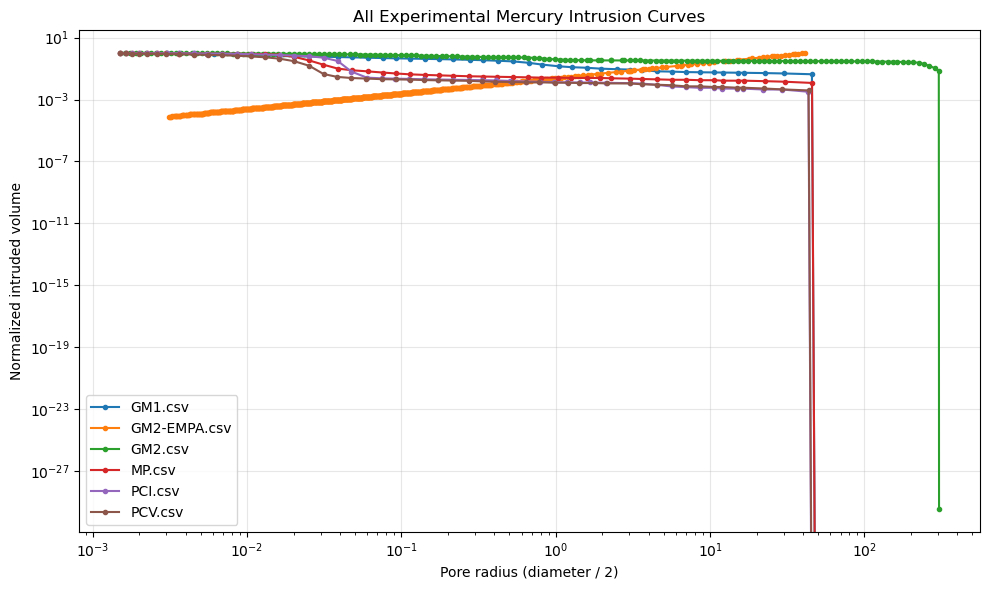

In [3]:
fig, ax = plt.subplots(figsize=(10, 6))

all_data = {}
for i, fname in enumerate(csv_files):
    filepath = DATA_DIR / fname
    diam = []
    vol = []
    with open(filepath, "r", newline="") as infile:
        reader = csv.reader(infile, delimiter=";")
        next(reader)  # skip header
        for row in reader:
            if len(row) >= 2:
                diam.append(float(row[0].replace(",", ".")))
                vol.append(float(row[1].replace(",", ".")))
    diam = np.array(diam)
    vol = np.array(vol)
    sort_idx = np.argsort(diam)
    diam = diam[sort_idx]
    vol = vol[sort_idx]
    cum_vol = vol / vol.max() if vol.max() > 0 else vol
    ax.plot(diam / 2.0, cum_vol, 'o-', label=fname, markersize=3)
    all_data[fname] = (diam, vol)

ax.set_xlabel('Pore radius (diameter / 2)')
ax.set_ylabel('Normalized intruded volume')
ax.set_title('All Experimental Mercury Intrusion Curves')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xscale('log')
ax.set_yscale('log')

plt.tight_layout()
plt.show()


### Select the file to use



In [4]:
# ============================================================
# USER PARAMETER - select which file to use
# ============================================================
selected_file_index = 0  # change this to use a different file

selected_file = csv_files[selected_file_index]
filepath = DATA_DIR / selected_file
print(f"Selected file: {filepath}")

# Load the selected file
diameters = []
volumes_cum = []
with open(filepath, "r", newline="") as infile:
    reader = csv.reader(infile, delimiter=";")
    header = next(reader)
    print(f"Header: {header}")
    for row in reader:
        if len(row) >= 2:
            diameters.append(float(row[0].replace(",", ".")))
            volumes_cum.append(float(row[1].replace(",", ".")))

diameters = np.array(diameters)
volumes_cum = np.array(volumes_cum)

# Sort by diameter ascending
sort_idx = np.argsort(diameters)
diameters = diameters[sort_idx]
volumes_cum = volumes_cum[sort_idx]

print(f"Loaded {len(diameters)} data points")
print(f"Diameter range: {diameters.min():.3f} - {diameters.max():.3f}")


Selected file: /home/jlux/Nextcloud/Codes/python3/pnm/examples/data/GM1.csv
Header: ['\ufeffDiameter', 'Volume']
Loaded 47 data points
Diameter range: 0.006 - 355.307


## 3. Prepare Experimental Data




The experimental CSV gives the **cumulative intruded volume** vs diameter.
From this we derive:

1. **Throat (capillary) distribution** `volumes`: the volume intruded in each
   diameter class, computed as `-np.diff(volumes_cum)` (negative difference
   because diameters are sorted ascending while cumulative volume decreases
   when read from large to small pores).

2. **Pore distribution** `pdist`: predicted from the throat distribution using
   the corrective factor `e` and the pore-to-throat radius ratio `PRTRR`.
   The algorithm iteratively computes the pore distribution such that, when
   pores are connected by throats, the measured throat distribution is recovered.

The relationship uses:
- **`e`**: empirical corrective factor (e=1 means no correction)
- **`PRTRR`**: pore radius to throat radius ratio (typically 2)



In [5]:
# Throat radii (diameter / 2)
throat_radii = diameters / 2.0

# Throat volume distribution: -diff of cumulative volume
# volumes[i] = volume intruded in throat class i
volumes = -np.diff(volumes_cum)
volumes = np.array(volumes)
volumes = volumes / volumes.sum()  # normalize

# Remove the last radius (corresponds to Vint=0)
throat_radii = throat_radii[:-1]

# Apply threshold on cumulative probability (keep 95% of cumulative volume)
cumulative_proba = 0.95
maxindex = np.argwhere(np.cumsum(volumes) <= cumulative_proba).max()
minindex = 0
throat_radii = throat_radii[minindex:maxindex + 1]
volumes = volumes[minindex:maxindex]
volumes = volumes / volumes.sum()

# Recompute deltaR AFTER all slicing (to ensure consistent lengths)
deltaR = np.diff(throat_radii)
midradii = throat_radii[:-1] + deltaR * 0.5

print(f"Number of throat radius bins: {len(throat_radii) - 1}")
print(f"Throat radius range: {throat_radii.min():.4f} - {throat_radii.max():.4f}")
print(f"Max fraction radius: {throat_radii[np.argmax(volumes)]:.4f}")


Number of throat radius bins: 42
Throat radius range: 0.0030 - 16.5191
Max fraction radius: 0.0106


### Predict pore distribution from throat distribution



pdist min: 0.000000
pdist max: 0.211165, sum: 1.000000


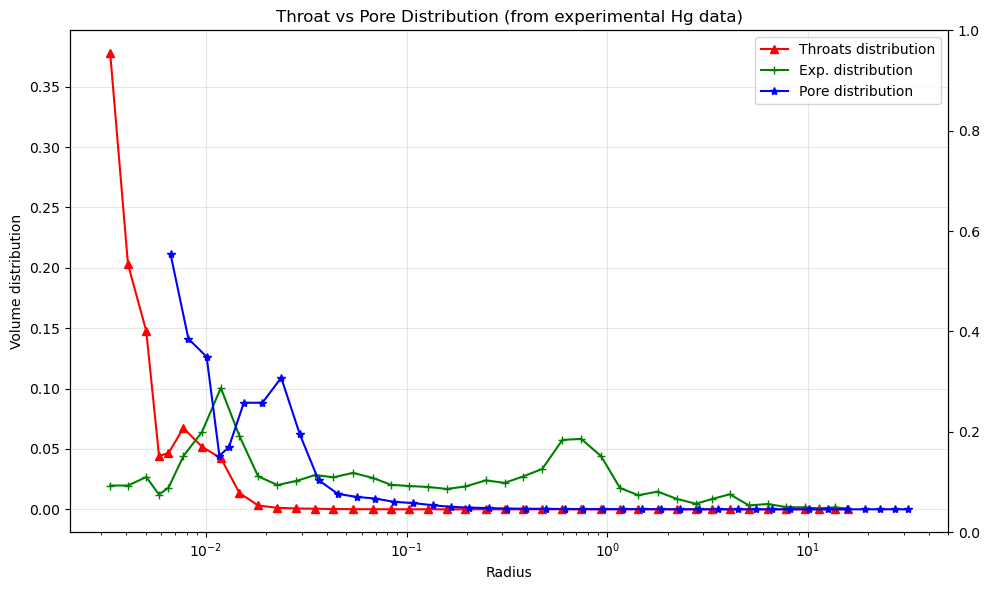

In [6]:
# ============================================================
# USER PARAMETERS - modify these values as needed
# ============================================================
e = 1.5                          # empirical corrective factor (1 = no correction)
PRTRR = 2.0                      # pore radius to throat radius ratio
# ============================================================

# cdist: normalized throat volume distribution with corrective factor e
cdist = np.array([
    volumes[i] / (np.pi * (midradii[i]**2 + (1.0/3) * deltaR[i]**2)**e)
    for i in range(len(volumes))
])
cdist /= cdist.sum()
cumcdist = np.cumsum(cdist)

# pdist: predicted pore distribution from throat distribution
# Iterative algorithm from the original notebook
pdist = np.zeros_like(cdist)
pdist[-1] = np.sqrt(cdist[-1])
for i in range(pdist.size - 1, -1, -1):
    pdist[i] = -pdist[i+1:].sum() + np.sqrt(pdist[i+1:].sum()**2 + cdist[i])

print(f"pdist min: {pdist.min():.6f}")
print(f"pdist max: {pdist.max():.6f}, sum: {pdist.sum():.6f}")

# Visualize: throat distribution vs experimental vs predicted pore distribution
fig, ax1 = plt.subplots(figsize=(10, 6))
ax2 = ax1.twinx()

ax1.plot(midradii, cdist, '^-', c='red', label='Throats distribution')
ax1.plot(midradii, volumes, '+-', c='green', label='Exp. distribution')
ax1.plot(midradii * PRTRR, pdist, '*-', c='blue', label='Pore distribution')

ax1.set_xlabel('Radius')
ax1.set_ylabel('Volume distribution')
ax1.set_title('Throat vs Pore Distribution (from experimental Hg data)')
ax1.set_xscale('log')
ax1.legend()
ax1.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Pore radius bins for network generation



In [7]:
# Pore radius bins = throat radii * PRTRR
pore_radii_bins = throat_radii * PRTRR
pore_deltaR = deltaR * PRTRR
pore_midradii = midradii * PRTRR

print(f"Pore radius range: {pore_radii_bins[0]:.4f} - {pore_radii_bins[-1]:.4f}")


Pore radius range: 0.0061 - 33.0383


## 4. Model Parameters




Parameters below are easily modifiable. Change the values and re-run the cells
to explore different network configurations.

- **`npores`**: target number of pores in the network
- **`target_porosity`**: target pore-body porosity
- **`sratio`**: maximal pore surface covered by throats ratio (constant or 4-tuple for Gaussian distribution)
- **`minc` / `maxc`**: minimum / maximum pore connectivity



In [8]:
# ============================================================
# USER PARAMETERS - modify these values as needed
# ============================================================
npores = 2000                    # target number of pores
target_porosity = 0.35           # target pore-body porosity
sratio = 0.75                    # max pore surface covered by throats (constant)
# sratio = (0.7, 0.4, 0.9, 0.15)  # alternative: Gaussian (loc, low, high, sigma)
minc = 2                         # minimum pore connectivity
maxc = 512                       # maximum pore connectivity
BCgridsize = 100                 # grid resolution for boundary detection
# ============================================================

print("Model parameters:")
print(f"  npores = {npores}")
print(f"  target_porosity = {target_porosity}")
print(f"  e = {e}")
print(f"  PRTRR = {PRTRR}")
print(f"  sratio = {sratio}")
print(f"  minc = {minc}, maxc = {maxc}")


Model parameters:
  npores = 2000
  target_porosity = 0.35
  e = 1.5
  PRTRR = 2.0
  sratio = 0.75
  minc = 2, maxc = 512


## 5. Generate Pore Network




We generate a random packing of pores using the **predicted pore distribution**
`pdist` (derived from the experimental throat distribution). The pore radius
bins are `throat_radii * PRTRR`.

The packing uses the fast **cell-list** algorithm (`packing_method="cell"`)
which is suitable for networks with tens of thousands of pores.



In [9]:
# Build radius distribution from predicted pore distribution
rdist = partial(
    inverse_transform_sampling_from_raw_data,
    pdist,
    bins=pore_radii_bins[:-1],
    high=np.inf,
)

print("Radius distribution: predicted pore distribution from experimental throat data")
print(f"  Pore bins: {len(pore_radii_bins) - 1} bins from {pore_radii_bins[0]:.4f} to {pore_radii_bins[-1]:.4f}")

# Generate the network
print("Generating pore network...")
pn = random_PNM(
    npores=npores,
    extent=(1.0, 1.0, 1.0),
    porosity=target_porosity,
    rdist=rdist,
    sratio=sratio,
    minc=minc,
    maxc=maxc,
    BCgridsize=BCgridsize,
    packing_method='cell',      # 'cell' = fast cell-list (recommended)
    packing_verbose=False,
)

print(f"\nGenerated network:")
print(f"  Number of pores: {pn.graph.number_of_nodes()}")
print(f"  Number of throats: {pn.graph.number_of_edges()}")
print(f"  Extent: {pn.graph.graph.get('extent')}")
print(f"  Porosity: {pn.graph.graph.get('porosity'):.4f}")

# Compute geometry
pn.compute_geometry(autothroats=True)
print(f"  Geometry complete: {pn.geom_complete}")


Radius distribution: predicted pore distribution from experimental throat data
  Pore bins: 42 bins from 0.0061 to 33.0383
Generating pore network...


2000 nodes to process
Iteration 0:  100.00% completed  


Iteration 1:  100.00% completed  


Creating 176 periodic links between face x- and face x+
Creating 410 periodic links between face y- and face y+

Generated network:
  Number of pores: 2000
  Number of throats: 4162
  Extent: [np.float64(3.507134827624906), np.float64(3.506942026246823), np.float64(3.504297761000252)]
  Porosity: 0.4400
  Geometry complete: True


### Save the generated network



In [10]:
timestamp = datetime.now().strftime("%Y%m%d-%H%M%S")
extent_list = pn.graph.graph.get("extent", [1.0, 1.0, 1.0])
extent_str = "x".join(f"{ev:.2f}" for ev in extent_list)
porosity_val = pn.graph.graph.get("porosity", 0.0)
porosity_str = f"{porosity_val*100:.2f}"
sratio_val = sratio[0] if isinstance(sratio, (list, tuple)) else float(sratio)
net_filename = (
    f"{timestamp}_{selected_file[:-4]}-NP{pn.graph.number_of_nodes()}-"
    f"{extent_str}-p{porosity_str}-SR{sratio_val:.2f}-"
    f"PT_RATIO{PRTRR:.2f}.gml"
)
net_path = NETWORKS_DIR / net_filename

pn.write(str(net_path), method='gml')
print(f"Network saved to: {net_path}")


Network saved to: /home/jlux/Nextcloud/Codes/python3/pnm/examples/networks/20261109-171930_GM1-NP2000-3.51x3.51x3.50-p44.00-SR0.75-PT_RATIO2.00.gml


## 6. Compare Experimental vs Generated Distributions




We compare the experimental **throat** distribution against the throat and pore
distributions measured on the generated network.

Two y-axes are used: the left axis shows the **non-cumulative** distribution
(bars), the right axis shows the **cumulative** distribution (line). A log
scale on y improves readability for wide-ranging values.



In [11]:
# Compute statistics on the generated network
rbins = throat_radii  # use the same bins as experimental data

pore_bins, pore_dist = stats(
    pn, bins=rbins, mode='vol', elements='pores', xscale='log', show=False
)
throat_bins, throat_dist = stats(
    pn, bins=rbins, mode='vol', elements='throats', xscale='log', show=False
)

# Normalize
pore_dist_norm = pore_dist / pore_dist.sum() if pore_dist.sum() > 0 else pore_dist
throat_dist_norm = throat_dist / throat_dist.sum() if throat_dist.sum() > 0 else throat_dist

print(f"Generated pore volume distribution (non-zero bins: {(pore_dist_norm>0).sum()}/{len(pore_dist_norm)})")
print(f"Generated throat volume distribution (non-zero bins: {(throat_dist_norm>0).sum()}/{len(throat_dist_norm)})")


Generated pore volume distribution (non-zero bins: 24/42)
Generated throat volume distribution (non-zero bins: 23/42)


<Figure size 640x480 with 0 Axes>

### Plot comparison



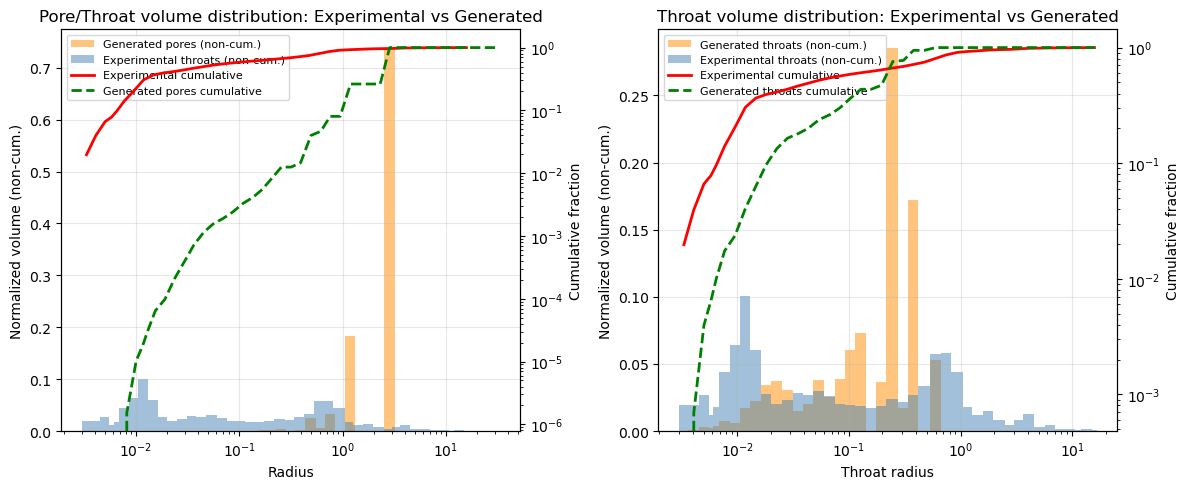

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# --- Pore distribution comparison ---
# Left axis: non-cumulative volume distribution (bars)
# Right axis: cumulative distribution (line)
bars1 = ax1.bar(pore_midradii, pore_dist_norm, width=pore_deltaR, alpha=0.5,
                label='Generated pores (non-cum.)', color='darkorange')
bars1b = ax1.bar(midradii, volumes, width=deltaR, alpha=0.5,
                 label='Experimental throats (non-cum.)', color='steelblue')
ax1_cum = ax1.twinx()
line1, = ax1_cum.plot(midradii, np.cumsum(volumes), 'r-', lw=2,
                      label='Experimental cumulative')
line2, = ax1_cum.plot(pore_midradii, np.cumsum(pore_dist_norm), 'g--', lw=2,
                      label='Generated pores cumulative')
ax1.set_xlabel('Radius')
ax1.set_ylabel('Normalized volume (non-cum.)')
ax1_cum.set_ylabel('Cumulative fraction')
ax1.set_title('Pore/Throat volume distribution: Experimental vs Generated')
ax1.set_xscale('log')
ax1_cum.set_yscale('log')
ax1.grid(True, alpha=0.3)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax1_cum.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=8)

# --- Throat distribution comparison ---
bars3 = ax2.bar(midradii, throat_dist_norm, width=deltaR, alpha=0.5,
                label='Generated throats (non-cum.)', color='darkorange')
bars4 = ax2.bar(midradii, volumes, width=deltaR, alpha=0.5,
                label='Experimental throats (non-cum.)', color='steelblue')
ax2_cum = ax2.twinx()
line3, = ax2_cum.plot(midradii, np.cumsum(volumes), 'r-', lw=2,
                      label='Experimental cumulative')
line4, = ax2_cum.plot(midradii, np.cumsum(throat_dist_norm), 'g--', lw=2,
                      label='Generated throats cumulative')
ax2.set_xlabel('Throat radius')
ax2.set_ylabel('Normalized volume (non-cum.)')
ax2_cum.set_ylabel('Cumulative fraction')
ax2.set_title('Throat volume distribution: Experimental vs Generated')
ax2.set_xscale('log')
ax2_cum.set_yscale('log')
ax2.grid(True, alpha=0.3)
h1, l1 = ax2.get_legend_handles_labels()
h2, l2 = ax2_cum.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()


## 7. Mercury Intrusion Simulation




We run a mercury intrusion simulation on the generated network and compare
the intrusion curve against the experimental data.

Note: experimental diameters are converted to radii (diameter / 2) for comparison.



In [13]:
# Run mercury intrusion on the generated network
print("Running mercury intrusion simulation...")
Dlist, vint = mercury_intrusion(
    pn,
    faces=("x-", "x+", "y-", "y+", "z-", "z+"),
    D_ratio=1.2,
    Dmax=10.0,
    Dmin=0.01,
    verbose=False,
)

print(f"Intrusion steps: {len(Dlist)}")
print(f"Total intruded volume: {sum(vint):.6f}")

# Normalize by total void volume
total_void = pn.pores_volume + pn.throats_volume
print(f"Total void volume: {total_void:.6f}")
print(f"Intrusion fraction: {sum(vint) / total_void:.4f}")


Running mercury intrusion simulation...
Filling pores with entrance diameter >= 1.00e+01.
Filling pores with entrance diameter >= 8.33e+00.
Filling pores with entrance diameter >= 6.94e+00.
Filling pores with entrance diameter >= 5.79e+00.
Filling pores with entrance diameter >= 4.82e+00.
Filling pores with entrance diameter >= 4.02e+00.
Filling pores with entrance diameter >= 3.35e+00.
Filling pores with entrance diameter >= 2.79e+00.
Filling pores with entrance diameter >= 2.33e+00.
Filling pores with entrance diameter >= 1.94e+00.
Filling pores with entrance diameter >= 1.62e+00.
Filling pores with entrance diameter >= 1.35e+00.
Filling pores with entrance diameter >= 1.12e+00.
Filling pores with entrance diameter >= 9.35e-01.
Filling pores with entrance diameter >= 7.79e-01.
Filling pores with entrance diameter >= 6.49e-01.
Filling pores with entrance diameter >= 5.41e-01.
Filling pores with entrance diameter >= 4.51e-01.
Filling pores with entrance diameter >= 3.76e-01.
Filling po

### Plot experimental vs simulated intrusion curves



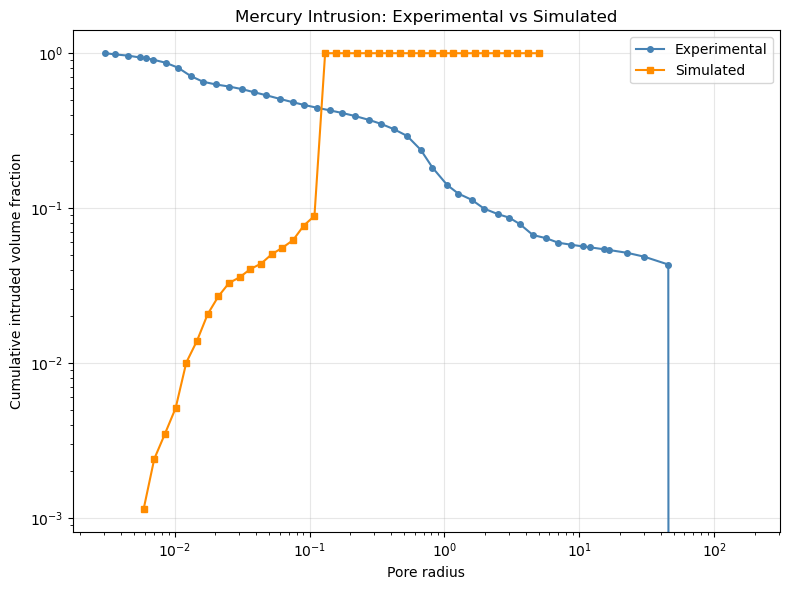

In [14]:
# Experimental intrusion: volume vs diameter (convert diameter -> radius)
# Use the cumulative volume from the original data (before thresholding)
exp_radii = diameters / 2.0
exp_cum_vol = volumes_cum / volumes_cum.max() if volumes_cum.max() > 0 else volumes_cum

# Simulated intrusion: Dlist contains diameters, convert to radius
sim_radii = np.array(Dlist[::-1]) / 2.0  # reverse order (smallest first)
sim_cum_vol = np.cumsum(np.array(vint[::-1])) / total_void

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(exp_radii, exp_cum_vol, 'o-', label='Experimental', color='steelblue', markersize=4)
ax.plot(sim_radii, sim_cum_vol, 's-', label='Simulated', color='darkorange', markersize=4)

ax.set_xlabel('Pore radius')
ax.set_ylabel('Cumulative intruded volume fraction')
ax.set_title('Mercury Intrusion: Experimental vs Simulated')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xscale('log')
ax.set_yscale('log')

plt.tight_layout()
plt.show()


## 8. 3D Visualization




We visualize the generated network using the fast `Fast3DViewer` (suitable for
large networks) and save a JPEG image of the 3D view.



In [15]:
from pnm.Visualization import Fast3DViewer, vtk_viewer

# Visualize and save image
img_filename = NETWORKS_DIR / f"view-{selected_file[:-4]}-NP{npores}.jpg"

print("Creating 3D visualization...")
vtk_viewer(
    pn,
    save=True,
    render=False,        # set True for interactive window
    camera=(20, 30),
    cmap='viridis',
    filename=str(img_filename),
    resolution=8,
    attr='radius',
)
print(f"3D image saved to: {img_filename}")

# Also create an interactive viewer (commented out - uncomment to use)
# viewer = Fast3DViewer(pn)
# viewer.render(resolution=8)
# viewer.interact(azimuth=20, elevation=30)


Creating 3D visualization...
Creating pore glyph actor (resolution=8)


3D image saved to: /home/jlux/Nextcloud/Codes/python3/pnm/examples/networks/view-GM1-NP2000.jpg


## Summary




This notebook demonstrated the complete workflow:

1. ✅ Read all experimental MIP data from CSV files and plot intrusion curves
2. ✅ Select one file and prepare the experimental throat distribution
3. ✅ Predict the pore distribution from the throat distribution (corrective factor `e`, PRTRR)
4. ✅ Define model parameters (npores, e, PRTRR, sratio, minc, maxc)
5. ✅ Generate a random pore network using the fast cell-list packing
6. ✅ Compare experimental vs generated pore and throat distributions
7. ✅ Run mercury intrusion simulation and compare intrusion curves
8. ✅ Visualize the network in 3D and save an image

The generated network has been saved to `examples/networks/`.

